In [1]:
from spf.dataset.spf_dataset import v5spfdataset

ds = v5spfdataset(
    # "/mnt/md2/rovers/merged_test/rover_2025_03_29_16_16_59_nRX2_center_spacing0p043_tag_RO3.rover_2025_03_29_16_11_30_nRX1_circle_spacing0p05075_tag_RO2.zarr",
    # "/mnt/md2/rovers/merged/rover_2025_03_29_16_14_54_nRX2_diamond_spacing0p035_tag_RO1.rover_2025_03_29_16_11_30_nRX1_circle_spacing0p05075_tag_RO2.zarr",
    "/mnt/md2/rovers/merged/rover_2025_03_22_19_55_11_nRX2_diamond_spacing0p035_tag_RO1.rover_2025_03_22_19_55_02_nRX1_circle_spacing0p05075_tag_RO2.zarr",
    # "/mnt/md2/rovers/merged/rover_2025_03_29_16_14_54_nRX2_diamond_spacing0p035_tag_RO1.rover_2025_03_29_16_11_30_nRX1_circle_spacing0p05075_tag_RO2.zarr",
    # "/mnt/md2/rovers/merged/rover_2025_03_29_17_34_29_nRX2_diamond_spacing0p035_tag_RO1.rover_2025_03_29_17_34_21_nRX1_circle_spacing0p05075_tag_RO2.zarr",
    # "/mnt/md2/2d_wallarray_v2_data/march_nuand/wallarrayv3_2025_03_29_19_03_59_nRX2_rx_random_circle_spacing0p025.zarr",
    # "/mnt/md2/2d_wallarray_v2_data/march/wallarrayv3_2025_03_15_11_18_30_nRX2_rx_random_circle_spacing0p043.zarr",
    # "/mnt/md2/2d_wallarray_v2_data/march_nuand/wallarrayv3_2025_03_29_14_52_33_nRX2_rx_random_circle_spacing0p025.zarr",
    nthetas=65,
    ignore_qc=True,
    precompute_cache="/mnt/md2/cache/precompute_cache_3p5_chunk1/",
    gpu=True,
    snapshots_per_session=1,
    n_parallel=8,
    paired=True,
    segmentation_version=3.5,
)

In [ ]:
import numpy as np


def detrend_1d_np_fast(x):
    """
    Optimized version of detrend_1d_np for fast baseline removal from a 1D array.
    Always assumes merge_similar=True.
    Returns the detrended array (original values minus piecewise linear trend).
    """
    # Convert input to numpy array of float for numerical operations
    x = np.asarray(x, dtype=float)
    n = x.size
    if n <= 1:
        # If zero or one element, trend is just the value itself (or none), so return zeros
        return np.zeros_like(x, dtype=float)
    # Prepare an array of indices (as float) to use as the independent variable for fitting
    idx = np.arange(n, dtype=float)

    # **Speedup**: Precompute prefix sums to allow O(1) retrieval of segment sum statistics.
    # This avoids using np.linalg.lstsq in a loop for each segment.
    prefix_y = np.cumsum(x)  # prefix sum of y values
    prefix_i = np.cumsum(idx)  # prefix sum of indices
    prefix_i2 = np.cumsum(idx * idx)  # prefix sum of index^2
    prefix_i_y = np.cumsum(idx * x)  # prefix sum of index*y

    # Identify initial segments by finding where the sign of the first difference changes.
    # This yields monotonic (non-increasing or non-decreasing) segments.
    diff = np.diff(x)
    sign = np.sign(diff)
    if sign.size > 0:
        # Propagate non-zero signs forward and backward through zero-difference regions
        # to avoid splitting flat regions unnecessarily.
        last_sign = 0.0
        for k in range(sign.size):
            if sign[k] == 0.0:
                sign[k] = last_sign
            else:
                last_sign = sign[k]
        last_sign = 0.0
        for k in range(sign.size - 1, -1, -1):
            if sign[k] == 0.0:
                sign[k] = last_sign
            else:
                last_sign = sign[k]
    # Determine breakpoints: start a new segment whenever the trend direction flips sign
    breakpoints = [0]
    for k in range(1, sign.size):
        if (
            sign[k] * sign[k - 1] < 0
        ):  # a sign flip (positive to negative or vice versa)
            breakpoints.append(k + 1)  # new segment starts at index k+1
    # Ensure the end of the array is a breakpoint
    if not breakpoints or breakpoints[-1] != n:
        breakpoints.append(n)

    # Create list of segment index ranges [(start_idx, end_idx), ...] using the breakpoints
    segments = [
        (breakpoints[i], breakpoints[i + 1]) for i in range(len(breakpoints) - 1)
    ]

    # Compute least-squares line (slope and intercept) for each segment using prefix sums (no explicit loops over data).
    seg_stats = []  # will store (N, sum_i, sum_y, sum_i2, sum_i_y) for each segment
    seg_slopes = []  # list of segment slopes
    # **Speedup**: Vectorized computation of sums via prefix arrays eliminates slow per-segment summing.
    for a, b in segments:
        # Segment covers indices [a, b) (end is exclusive in our breakpoints definition)
        N = b - a
        if N <= 1:
            # For segments of length 1 (or 0), define slope = 0 (no trend) and intercept = value (exact fit)
            slope = 0.0
            intercept = x[a] if N == 1 else 0.0
            # Compute stats for consistency (for N==1)
            sum_i = idx[a] if N == 1 else 0.0
            sum_y = x[a] if N == 1 else 0.0
            sum_i2 = idx[a] ** 2 if N == 1 else 0.0
            sum_i_y = idx[a] * x[a] if N == 1 else 0.0
        else:
            # Use prefix sums to get sums over [a, b-1] in O(1) time
            sum_i = prefix_i[b - 1] - (prefix_i[a - 1] if a > 0 else 0.0)
            sum_y = prefix_y[b - 1] - (prefix_y[a - 1] if a > 0 else 0.0)
            sum_i2 = prefix_i2[b - 1] - (prefix_i2[a - 1] if a > 0 else 0.0)
            sum_i_y = prefix_i_y[b - 1] - (prefix_i_y[a - 1] if a > 0 else 0.0)
            # Solve for slope and intercept using the closed-form solution for linear least squares:
            # slope = (N*sum(i*y) - sum(i)*sum(y)) / (N*sum(i^2) - (sum(i))^2)
            # intercept = (sum(y) - slope*sum(i)) / N
            denom = N * sum_i2 - sum_i * sum_i
            if denom == 0.0:
                slope = 0.0
                intercept = sum_y / N
            else:
                slope = (N * sum_i_y - sum_i * sum_y) / denom
                intercept = (sum_y - slope * sum_i) / N
        seg_stats.append((N, sum_i, sum_y, sum_i2, sum_i_y))
        seg_slopes.append(slope)
    seg_slopes = np.array(seg_slopes, dtype=float)

    # If only one segment, subtract its trend and return
    if seg_slopes.size <= 1:
        m = seg_slopes[0] if seg_slopes.size == 1 else 0.0
        c = x[0] if seg_slopes.size == 1 else 0.0  # if one segment of length 1
        return x - (m * idx + c)

    # Merge adjacent segments with similar slopes to simplify the baseline.
    # **Speedup**: Perform merging in a single pass instead of iterative merging of pairs.
    rel_threshold = 0.1  # relative slope difference threshold (e.g., 10%)
    abs_threshold = (
        1e-8  # absolute difference threshold for nearly equal (or very small) slopes
    )
    merged_segments = (
        []
    )  # will hold merged segment ranges and their combined fit (slope, intercept)
    i = 0
    while i < len(seg_slopes):
        # Start a new merged segment at segment i
        a_idx = segments[i][0]  # starting data index of this merged segment
        b_idx = segments[i][1]  # end (exclusive) data index of this merged segment
        # Initialize combined segment statistics with segment i
        N_comb, sum_i_c, sum_y_c, sum_i2_c, sum_i_y_c = seg_stats[i]
        # Compute initial combined slope and intercept for this merged segment
        denom = N_comb * sum_i2_c - sum_i_c * sum_i_c
        slope_c = (
            (N_comb * sum_i_y_c - sum_i_c * sum_y_c) / denom if denom != 0.0 else 0.0
        )
        intercept_c = (sum_y_c - slope_c * sum_i_c) / N_comb if N_comb != 0 else 0.0
        # Attempt to merge with following segments if slopes are within the defined threshold
        j = i
        while j < len(seg_slopes) - 1:
            next_slope = seg_slopes[j + 1]
            # Check if the next segment's slope is similar to the current merged slope
            if abs(next_slope - slope_c) <= abs_threshold or abs(
                next_slope - slope_c
            ) <= rel_threshold * max(abs(slope_c), abs(next_slope)):
                # Merge segment j+1 into the current segment by updating combined stats
                j += 1
                N2, si2, sy2, si2_2, siy2 = seg_stats[j]
                N_comb += N2
                sum_i_c += si2
                sum_y_c += sy2
                sum_i2_c += si2_2
                sum_i_y_c += siy2
                b_idx = segments[j][1]  # extend the merged segment end index
                # Recompute slope and intercept for the enlarged segment
                denom = N_comb * sum_i2_c - sum_i_c * sum_i_c
                slope_c = (
                    (N_comb * sum_i_y_c - sum_i_c * sum_y_c) / denom
                    if denom != 0.0
                    else 0.0
                )
                intercept_c = (
                    (sum_y_c - slope_c * sum_i_c) / N_comb if N_comb != 0 else 0.0
                )
            else:
                break  # stop merging if the next segment's slope is too different
        # Record the merged segment (from a_idx to b_idx) with its combined slope and intercept
        merged_segments.append((a_idx, b_idx, slope_c, intercept_c))
        # Continue with the next unmerged segment
        i = j + 1

    # Construct the detrended signal by subtracting each merged segment's line fit from the original signal.
    x_detrended = np.empty_like(x)
    for start, end, m, c in merged_segments:
        # Create baseline values for this segment: m*idx + c for idx in [start, end)
        # and subtract from the original signal.
        x_detrended[start:end] = x[start:end] - (m * idx[start:end] + c)
    return x_detrended

In [ ]:
import numpy as np


# by chatgpt
def detrend_1d_np_fastwindow(
    x: np.ndarray,
    window_size: int = 1024,
    pad_mode: str = "constant",
    pad_value: float = 0.0,
):
    """
    Detrend a 1D array by subtracting a linear trend in each fixed-size window.

    Parameters
    ----------
    x : np.ndarray
        Input 1D array.
    window_size : int
        Size of each segment/window.
    pad_mode : str
        How to pad if len(x) not divisible by window_size: 'constant', 'reflect', or 'replicate'.
    pad_value : float
        Value for constant padding.

    Returns
    -------
    x_detrended : np.ndarray
        Detrended output array, same length as input.
    """
    x = np.asarray(x, dtype=float)
    N = x.size

    # Pad if necessary
    remainder = N % window_size
    if remainder > 0:
        pad_len = window_size - remainder
        if pad_mode == "constant":
            pad = np.full(pad_len, pad_value)
        elif pad_mode == "reflect":
            pad = x[-pad_len:][::-1]
        elif pad_mode == "replicate":
            pad = np.repeat(x[-1], pad_len)
        else:
            raise ValueError(f"Unsupported pad_mode: {pad_mode}")
        x_padded = np.concatenate([x, pad])
    else:
        x_padded = x
        pad_len = 0

    # Reshape into windows
    x_win = x_padded.reshape(-1, window_size)
    nw = x_win.shape[0]

    # Create time index (same for all windows)
    t = np.linspace(0, 1, window_size)
    t = t[None, :]  # shape (1, window_size)

    # Compute means
    t_mean = np.mean(t)
    x_mean = np.mean(x_win, axis=1, keepdims=True)

    # Compute slopes using least squares closed form (vectorized)
    t_centered = t - t_mean
    x_centered = x_win - x_mean

    denom = np.sum(t_centered**2)
    slopes = np.sum(t_centered * x_centered, axis=1) / denom

    # Intercepts: mean(x) - slope * mean(t)
    intercepts = x_mean[:, 0] - slopes * t_mean

    # Reconstruct trends
    trends = slopes[:, None] * t + intercepts[:, None]

    # Subtract trend
    x_detrended = x_win - trends

    # Flatten and trim
    x_detrended = x_detrended.reshape(-1)
    if pad_len > 0:
        x_detrended = x_detrended[:-pad_len]

    return x_detrended

In [ ]:
import numpy as np
import time

from spf.sdrpluto.detrend import detrend_1d_np

# Generate a large test signal
x = np.linspace(0, 1, 10**6) + 0.01 * np.random.randn(10**6)

# Your original function (assuming it's named detrend_1d_np)
start = time.time()
_ = detrend_1d_np(x, remove=True, merge_similar=True)[0]
print("Original:", time.time() - start, "seconds")

# Optimized version
start = time.time()
_ = detrend_1d_np_fastwindow(x, window_size=1024)
print("Optimized:", time.time() - start, "seconds")

Original: 0.059250593185424805 seconds


NameError: name 'detrend_1d_np_fastwindow' is not defined

In [ ]:
import numpy as np
import time

from spf.sdrpluto.detrend import detrend_1d_np, detrend_np

session_idx = 100
rx_idx = 0
data = ds[session_idx][rx_idx]

n = data["signal_matrix"].shape[3]

# Generate a large test signal
x = np.linspace(0, 1, 10**6) + 0.01 * np.random.randn(10**6)

# Your original function (assuming it's named detrend_1d_np)
start = time.time()
_ = raw_radio_values = detrend_np(data["signal_matrix"][0, 0].numpy())
print("Original:", time.time() - start, "seconds")

# Optimized version
start = time.time()
_ = detrend_1d_np_fastwindow(data["signal_matrix"][0, 0].numpy(), window_size=1024)
print("Optimized:", time.time() - start, "seconds")

Original: 0.10408854484558105 seconds
Optimized: 0.005089759826660156 seconds


/tmp/ipykernel_3515343/1695139939.py:23: ComplexWarning: Casting complex values to real discards the imaginary part
  x = np.asarray(x, dtype=float)


In [ ]:
from spf.sdrpluto.detrend import detrend_np
import os
from spf.rf import beamformer_given_steering_nomean, get_phase_diff
import matplotlib.pyplot as plt
import numpy as np
from spf.dataset.segmentation import default_segment_args, simple_segment

# look at radio rx_idx
rx_idx = 0
# load up the session_idx'th buffer in this recording and plot parts of it
session_idx = 4
offset = 0  # offset inside of buffer

data = ds[session_idx][rx_idx]

n = data["signal_matrix"].shape[3]

#
raw_radio_values = detrend_np(
    data["signal_matrix"][0, 0, :, offset : offset + n].numpy()
)
phase_difference = get_phase_diff(raw_radio_values)

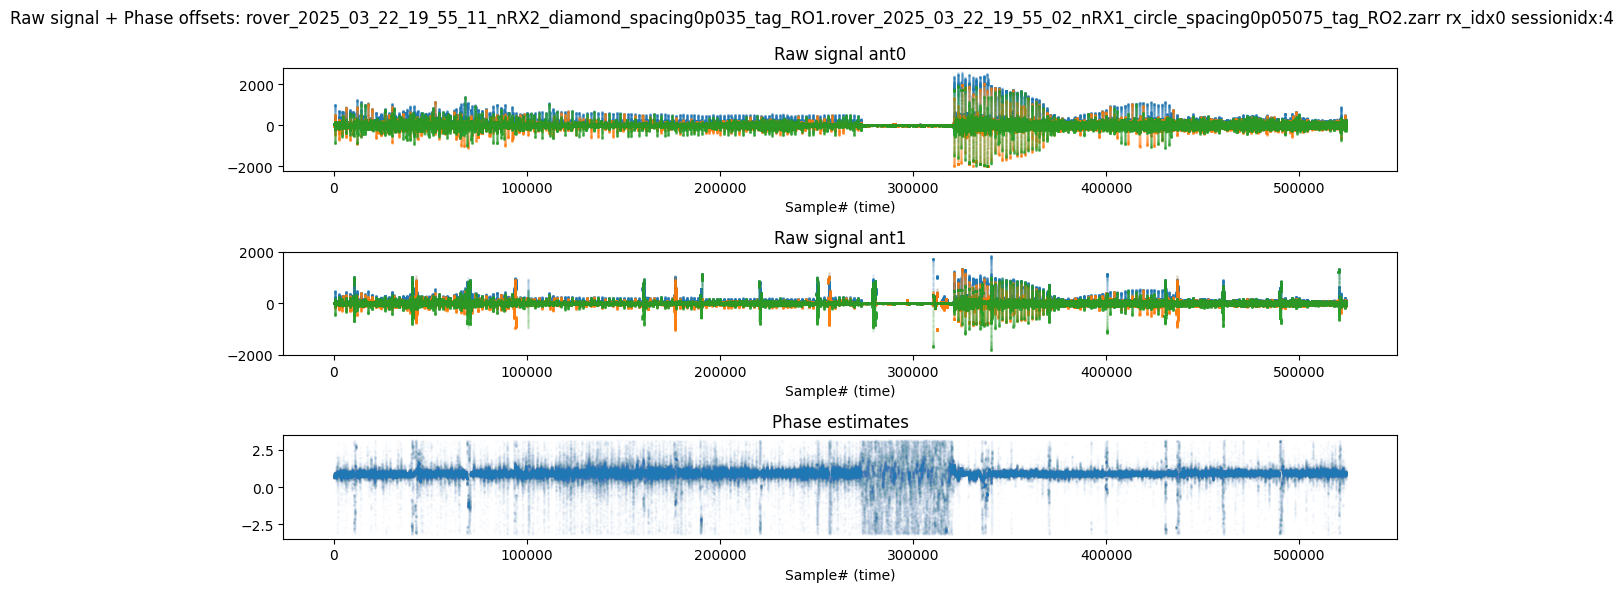

In [ ]:
#
fig, axs = plt.subplots(3, 1, figsize=(12, 6))
fig.suptitle(
    f"Raw signal + Phase offsets: {os.path.basename(ds.zarr_fn)} rx_idx{rx_idx} sessionidx:{session_idx}"
)
axs[0].scatter(np.arange(n), np.abs(raw_radio_values[0]), alpha=0.1, s=1, label="ant0")
axs[0].scatter(np.arange(n), raw_radio_values[0].real, alpha=0.1, s=1, label="ant0 r")
axs[0].scatter(np.arange(n), raw_radio_values[0].imag, alpha=0.1, s=1, label="ant0 i")
axs[0].set_title("Raw signal ant0")
axs[1].scatter(np.arange(n), np.abs(raw_radio_values[1]), alpha=0.1, s=1, label="ant0")
axs[1].scatter(np.arange(n), raw_radio_values[1].real, alpha=0.1, s=1, label="ant0 r")
axs[1].scatter(np.arange(n), raw_radio_values[1].imag, alpha=0.1, s=1, label="ant0 i")
axs[1].set_title("Raw signal ant1")
axs[0].set_xlabel("Sample# (time)")
axs[1].set_xlabel("Sample# (time)")
axs[2].set_xlabel("Sample# (time)")
axs[2].set_title("Phase estimates")
axs[2].scatter(np.arange(n), phase_difference, s=1, alpha=0.01)

beamformer_output = [
    beamformer_given_steering_nomean(
        steering_vectors=ds.steering_vectors[receiver_idx],
        signal_matrix=raw_radio_values,
    )
    for receiver_idx in range(2)
]

window_sds = []
for window in simple_segment(raw_radio_values, **default_segment_args)[
    "simple_segmentation"
]:
    print(window)
    if window["type"] == "signal":
        axs[1].plot(
            [window["start_idx"], window["end_idx"]],
            [window["mean"], window["mean"]],
            color="red",
        )
    else:
        axs[1].plot(
            [window["start_idx"], window["end_idx"]],
            [window["mean"], window["mean"]],
            color="orange",
        )
    _beam_sds = beamformer_output[0][:, window["start_idx"] : window["end_idx"]].mean(
        axis=1
    )
    window_sds.append(_beam_sds)
window_sds = np.array(window_sds)
fig.set_tight_layout(True)